# Ecualización de histogramas RGB hecha a mano

Este notebook reproduce tu código de MATLAB (`histeq`, `imadjust`, `subplot`...) **sin usar ninguna función de ecualización**.
Todo el proceso de normalizar el histograma se programa paso a paso con NumPy.

**Flujo:**
1. Subir la imagen
2. Ver los histogramas **reales** (originales) de R, G y B
3. Ecualizar cada canal a mano (histograma → CDF → tabla LUT → aplicar)
4. Ver los histogramas **ya normalizados**
5. Unir los canales y comparar
6. Ajuste de luminosidad (`imadjust` con gamma, hecho a mano)
7. Controles interactivos para subir/bajar luminosidad y mover cada color

Ejecuta las celdas **una por una** (Shift + Enter).

## 1. Librerías
Solo para leer la imagen, hacer cálculos con arreglos y graficar. **Ninguna ecualiza.**

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image          # solo para leer la imagen

plt.rcParams['figure.dpi'] = 110


## 2. Cargar y mostrar la imagen


Archivo: High Res Wallpaper HD.jpg | Tamaño: (414, 736, 3) | tipo: uint8


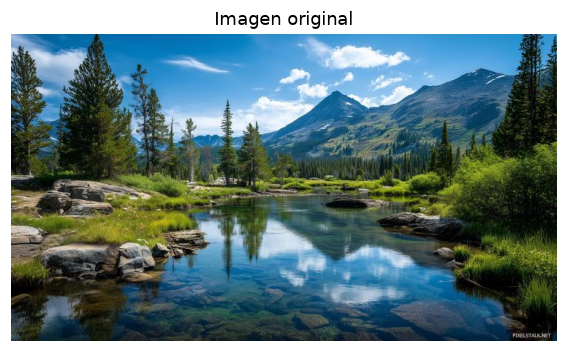

In [2]:
RUTA = 'High Res Wallpaper HD.jpg'

img = np.array(Image.open(RUTA).convert('RGB'))   # alto x ancho x 3, uint8 (0-255)
print('Archivo:', RUTA, '| Tamaño:', img.shape, '| tipo:', img.dtype)

plt.imshow(img)
plt.title('Imagen original')
plt.axis('off')
plt.show()


## 3. Separación de canales y cálculo matemático de histogramas reales

Cada imagen en color está formada por 3 matrices 2D: **R (Rojo)**, **G (Verde)** y **B (Azul)**.
- Cada matriz contiene valores enteros de $0$ a $255$.
- Un canal individual se puede visualizar de dos formas:
  1. **En escala de grises (Intensidad pura):** blanco = máxima presencia de ese color, negro = ausencia de ese color (como hace MATLAB con `imshow(R)`).
  2. **En color aislado (RGB):** dejando activo solo ese plano y poniendo los otros dos en cero (ej. `[0, 0, B]` para azul puro).

**Histograma matemático a mano:**
$$ h(r_k) = n_k $$
donde $n_k$ es la cantidad de píxeles con nivel de intensidad $k$ ($0 \le k \le 255$).
Lo programamos contando elemento por elemento, sin librerías de ecualización ni cajas negras.


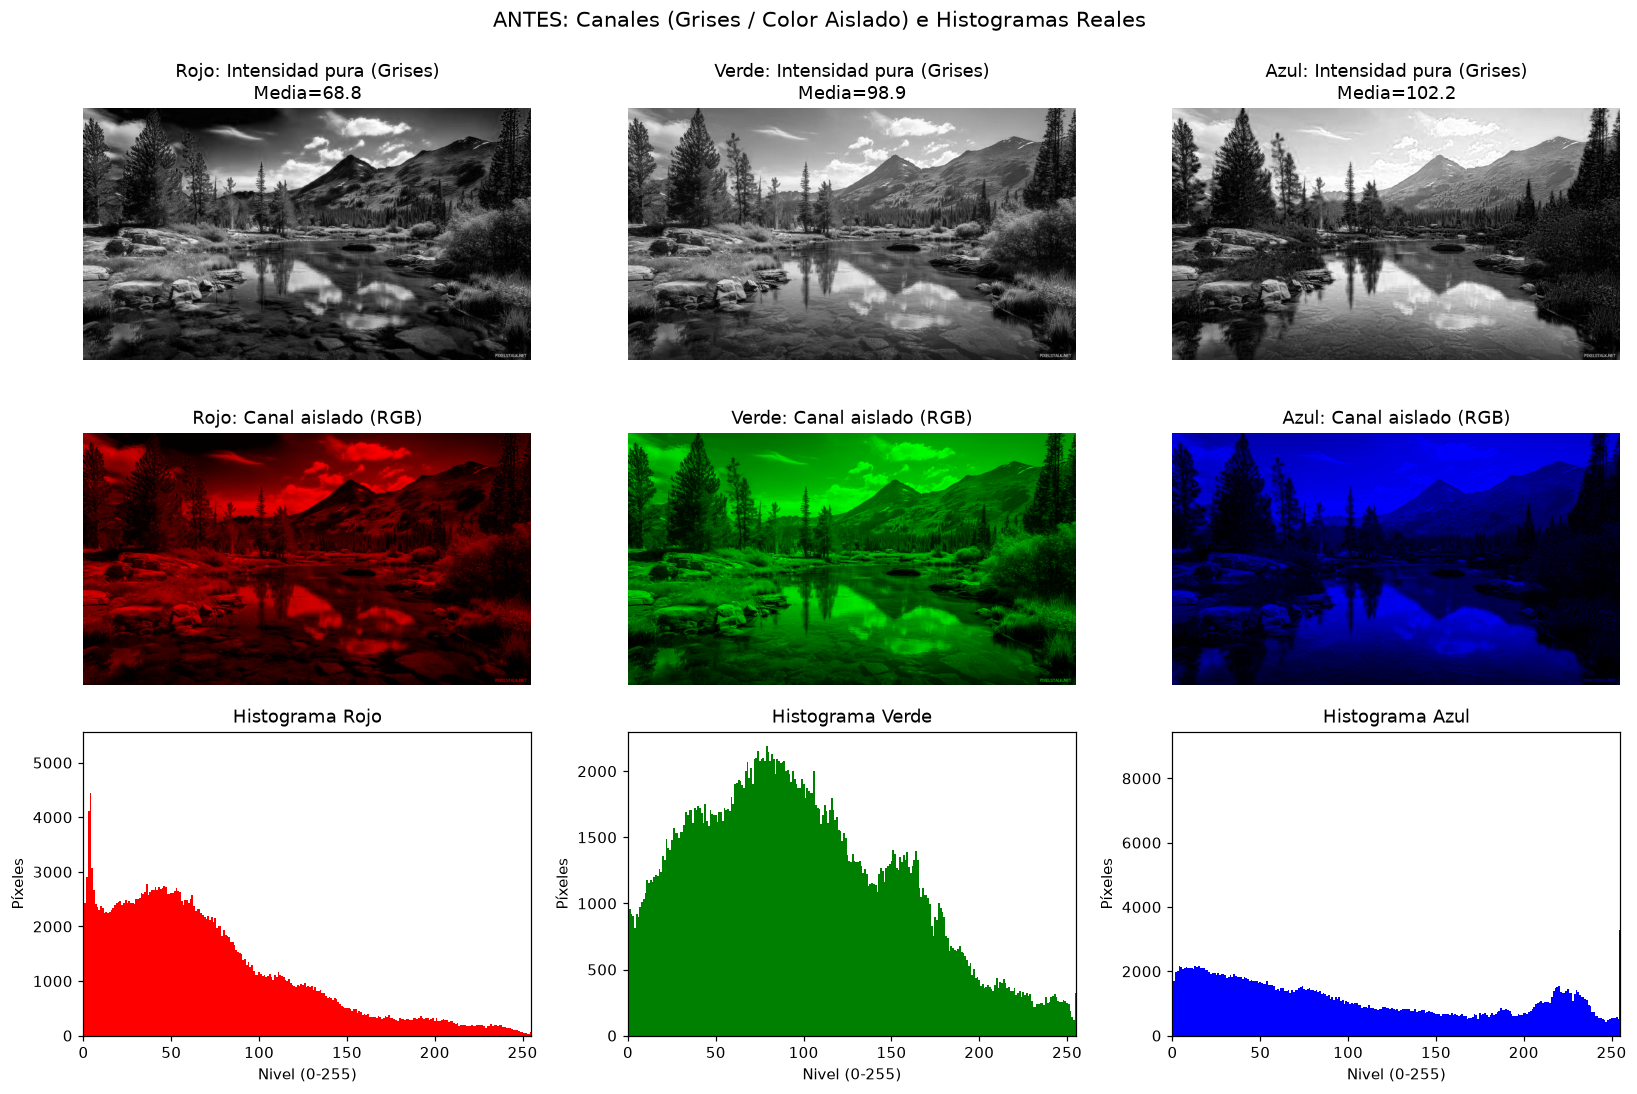

In [3]:
# Separación directa de los 3 planos de color (matrices 2D de dimensiones alto x ancho)
R, G, B = img[:, :, 0], img[:, :, 1], img[:, :, 2]
N_total = R.size   # Total de píxeles (alto * ancho)

def histograma_manual(canal):
    """
    Cálculo matemático del histograma a mano:
    Recorre los píxeles y cuenta cuántas veces aparece cada nivel 0..255.
    """
    h = np.zeros(256, dtype=int)
    for pixel in canal.ravel():
        h[pixel] += 1
    return h

# Alias 'histograma' para compatibilidad en todo el cuaderno
histograma = histograma_manual

hR = histograma_manual(R)
hG = histograma_manual(G)
hB = histograma_manual(B)

def solo_canal(canal, indice):
    """Genera una imagen RGB con solo el canal indicado activo (como en MATLAB)."""
    out = np.zeros((*canal.shape, 3), dtype=np.uint8)
    out[:, :, indice] = canal
    return out

def mostrar_canales_completo(cR, cG, cB, hR, hG, hB, titulo):
    fig, ax = plt.subplots(3, 3, figsize=(15, 10))
    canales = [(cR, hR, 'Rojo', 'red', 0), (cG, hG, 'Verde', 'green', 1), (cB, hB, 'Azul', 'blue', 2)]
    for col, (c, h, nombre, color_bar, ch_idx) in enumerate(canales):
        # Fila 1: Intensidad pura en escala de grises
        ax[0, col].imshow(c, cmap='gray')
        ax[0, col].set_title(f'{nombre}: Intensidad pura (Grises)\nMedia={c.mean():.1f}')
        ax[0, col].axis('off')
        # Fila 2: Canal aislado con su color propio
        ax[1, col].imshow(solo_canal(c, ch_idx))
        ax[1, col].set_title(f'{nombre}: Canal aislado (RGB)')
        ax[1, col].axis('off')
        # Fila 3: Histograma
        ax[2, col].bar(range(256), h, color=color_bar, width=1.0)
        ax[2, col].set_xlim(0, 255); ax[2, col].set_xlabel('Nivel (0-255)'); ax[2, col].set_ylabel('Píxeles')
        ax[2, col].set_title(f'Histograma {nombre}')
    fig.suptitle(titulo, fontsize=14, y=0.99)
    plt.tight_layout()
    plt.show()

mostrar_canales_completo(R, G, B, hR, hG, hB, 'ANTES: Canales (Grises / Color Aislado) e Histogramas Reales')


## 4. Ecualización manual de histograma (Fundamento matemático formal)

Siguiendo la teoría canónica de procesamiento digital de imágenes (González & Woods), el proceso se define en 5 pasos matemáticos exactos **sin utilizar ninguna librería de ecualización**:

1. **Histograma de frecuencias:** $h[k] = n_k$ (conteo de píxeles con intensidad $k$).
2. **Histograma normalizado / Función de Probabilidad (PDF):**
   $$ p_r(r_k) = \frac{n_k}{N} \quad \text{donde } N = \text{total de píxeles y } \sum_{k=0}^{255} p_r(r_k) = 1 $$
3. **Función de Distribución Acumulada (CDF):**
   $$ CDF[k] = \sum_{j=0}^{k} p_r(r_j) $$
4. **Función de transformación / Tabla Look-Up Table (LUT):**
   Mapea cada nivel $k$ al nuevo nivel $s_k$ en el rango $[0, 255]$ estirando el rango dinámico:
   $$ LUT[k] = round\left( \frac{CDF[k] - CDF_{min}}{1.0 - CDF_{min}} \times 255 \right) $$
5. **Aplicación:** Se reemplaza cada píxel original con nivel $k$ por su valor mapeado $LUT[k]$.


In [4]:
def ecualizar_manual(canal):
    """
    Ecualización manual paso a paso:
    Retorna el canal transformado, la tabla LUT, la CDF, la PDF y el histograma.
    """
    N = canal.size
    
    # 1. Histograma (a mano)
    h = histograma_manual(canal)
    
    # 2. PDF (Histograma Normalizado / Probabilidad)
    pdf = h / N
    
    # 3. CDF (Suma acumulada de probabilidades)
    cdf = np.zeros(256, dtype=np.float64)
    acumulado = 0.0
    for k in range(256):
        acumulado += pdf[k]
        cdf[k] = acumulado
        
    # 4. Tabla de transformación (LUT)
    cdf_min = cdf[cdf > 0].min()
    if cdf_min >= 1.0:
        lut = np.arange(256, dtype=np.uint8)
    else:
        lut = np.round((cdf - cdf_min) / (1.0 - cdf_min) * 255.0)
        lut = np.clip(lut, 0, 255).astype(np.uint8)
        
    # 5. Aplicar tabla LUT a todos los píxeles
    canal_ecualizado = lut[canal]
    
    return canal_ecualizado, lut, cdf

# Ecualizar cada canal individualmente
redEq,   lutR, cdfR = ecualizar_manual(R)
greenEq, lutG, cdfG = ecualizar_manual(G)
blueEq,  lutB, cdfB = ecualizar_manual(B)

print('Verificación matemática de valores calculados (Muestra de niveles):')
print('Nivel | R_orig -> R_nuevo | G_orig -> G_nuevo | B_orig -> B_nuevo')
print('-' * 60)
for lvl in [0, 50, 100, 150, 200, 255]:
    print(f'{lvl:5d} | {lvl:6d} -> {lutR[lvl]:7d} | {lvl:6d} -> {lutG[lvl]:7d} | {lvl:6d} -> {lutB[lvl]:7d}')


Verificación matemática de valores calculados (Muestra de niveles):
Nivel | R_orig -> R_nuevo | G_orig -> G_nuevo | B_orig -> B_nuevo
------------------------------------------------------------
    0 |      0 ->       0 |      0 ->       0 |      0 ->       0
   50 |     50 ->     110 |     50 ->      59 |     50 ->      83
  100 |    100 ->     194 |    100 ->     140 |    100 ->     142
  150 |    150 ->     232 |    150 ->     202 |    150 ->     178
  200 |    200 ->     247 |    200 ->     241 |    200 ->     207
  255 |    255 ->     255 |    255 ->     255 |    255 ->     255


### Curvas de transformación (LUT)
Muestran cómo se movió cada nivel de intensidad. La diagonal punteada sería "no cambiar nada".

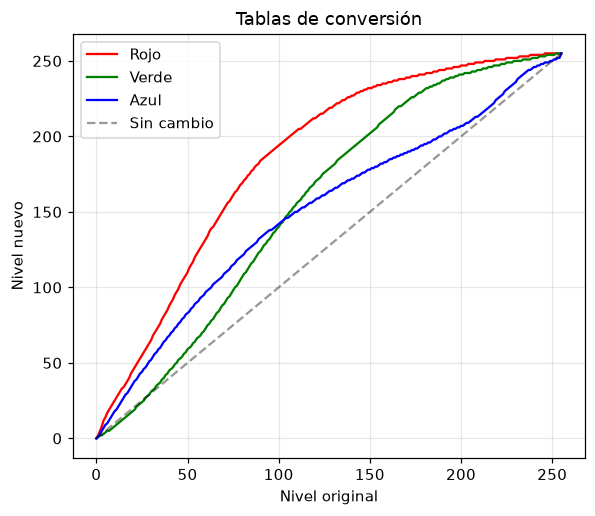

In [5]:
plt.figure(figsize=(6, 5))
plt.plot(lutR, 'r', label='Rojo'); plt.plot(lutG, 'g', label='Verde'); plt.plot(lutB, 'b', label='Azul')
plt.plot([0, 255], [0, 255], 'k--', alpha=.4, label='Sin cambio')
plt.xlabel('Nivel original'); plt.ylabel('Nivel nuevo'); plt.legend(); plt.grid(alpha=.3)
plt.title('Tablas de conversión'); plt.show()

## 5. Histogramas ya normalizados (DESPUÉS)

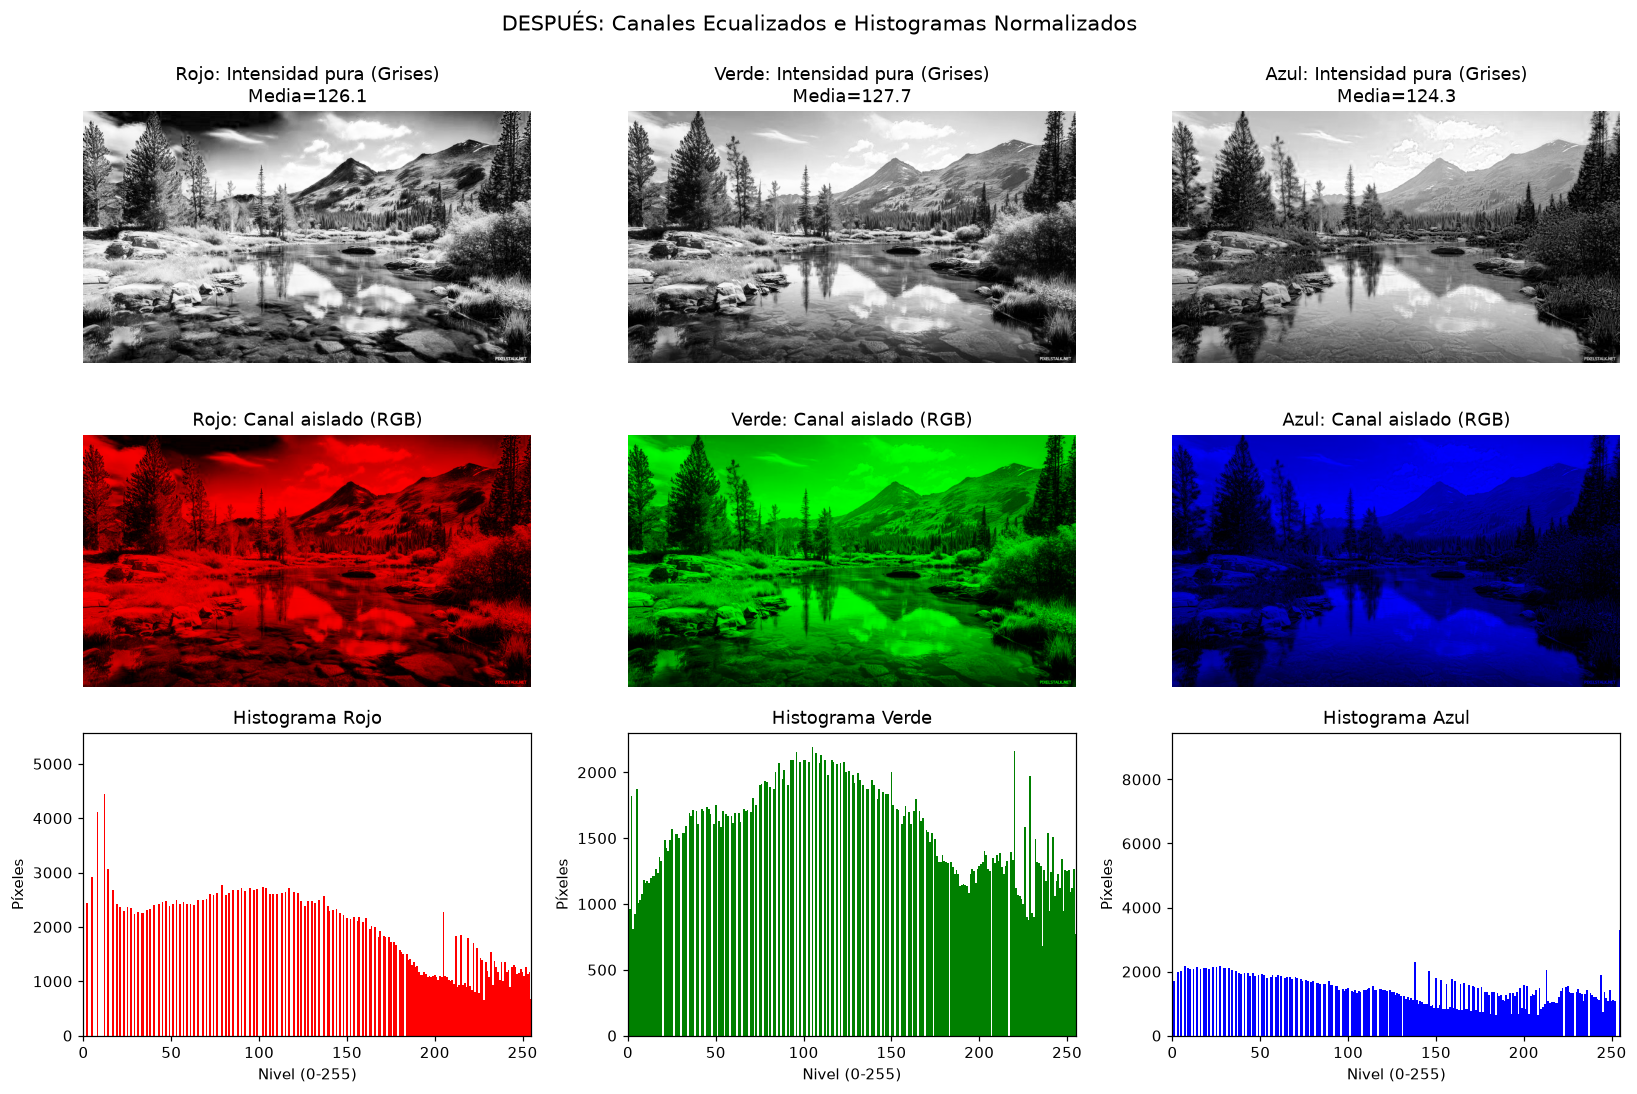

In [6]:
hRe = histograma_manual(redEq)
hGe = histograma_manual(greenEq)
hBe = histograma_manual(blueEq)
mostrar_canales_completo(redEq, greenEq, blueEq, hRe, hGe, hBe, 'DESPUÉS: Canales Ecualizados e Histogramas Normalizados')


### Comparación directa antes vs. después (histogramas superpuestos)

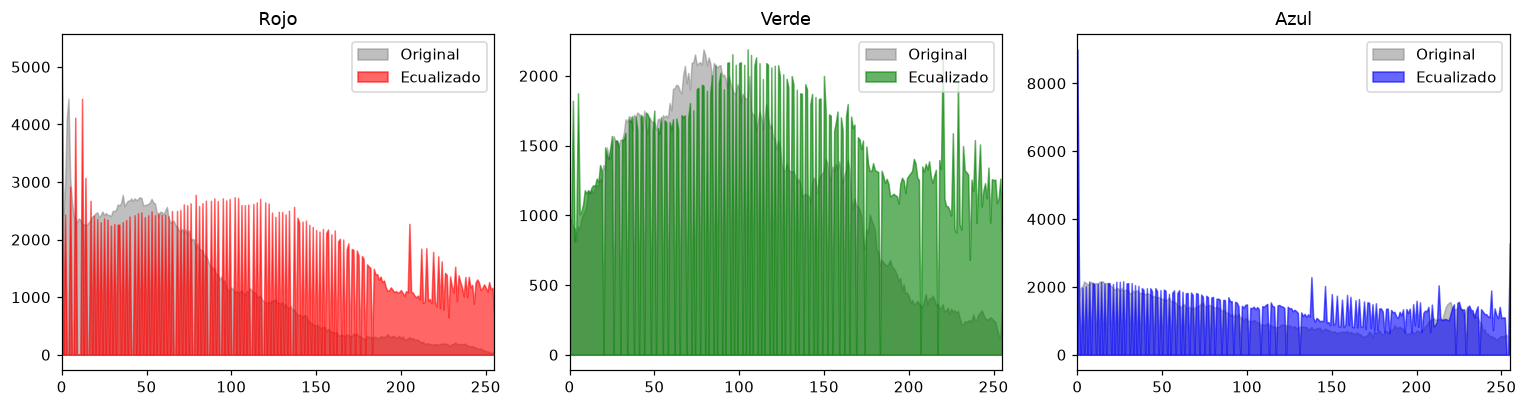

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for a, (ho, he, nombre, col) in zip(ax, [(hR, hRe, 'Rojo', 'red'), (hG, hGe, 'Verde', 'green'), (hB, hBe, 'Azul', 'blue')]):
    a.fill_between(range(256), ho, color='gray', alpha=.5, label='Original')
    a.fill_between(range(256), he, color=col, alpha=.6, label='Ecualizado')
    a.set_title(nombre); a.set_xlim(0, 255); a.legend()
plt.tight_layout(); plt.show()

## 6. Unir los canales de nuevo
Equivale a `cat(3, redEq, greenEq, blueEq)` de MATLAB.

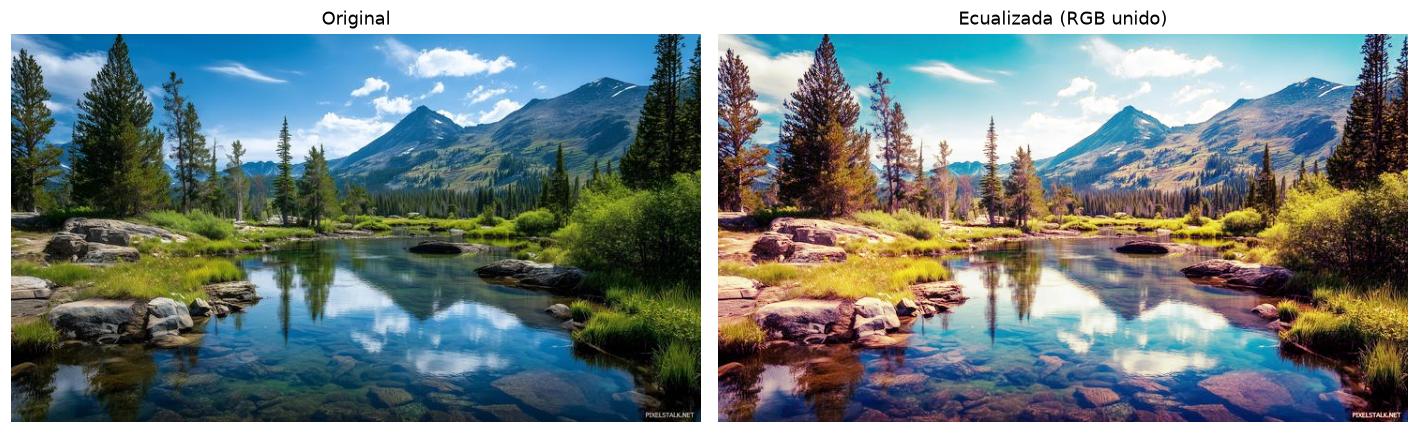

In [8]:
imgUnida = np.stack([redEq, greenEq, blueEq], axis=2)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].imshow(img);       ax[0].set_title('Original');             ax[0].axis('off')
ax[1].imshow(imgUnida);  ax[1].set_title('Ecualizada (RGB unido)'); ax[1].axis('off')
plt.tight_layout(); plt.show()

## 7. Luminosidad (`imadjust` con gamma, a mano)

En MATLAB: `imadjust(img, [], [], 1/luminosidad)` aplica una corrección gamma:

$$ salida = 255 \cdot \left(\frac{entrada}{255}\right)^{1/luminosidad} $$

- `luminosidad > 1` → imagen **más clara**
- `luminosidad < 1` → imagen **más oscura**

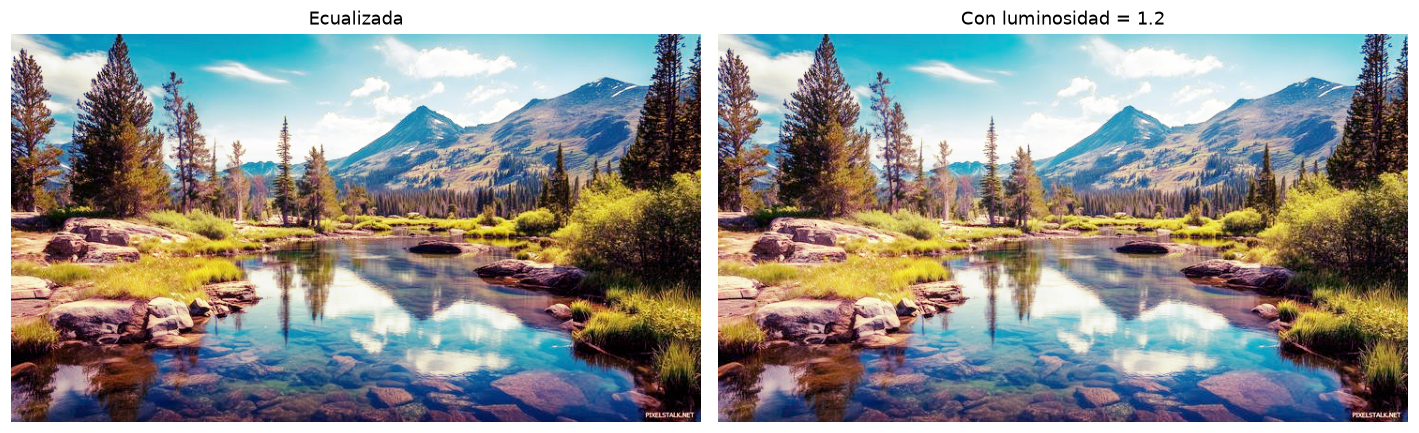

In [9]:
def ajustar_luminosidad(imagen, luminosidad):
    x = imagen.astype(np.float64) / 255.0       # normalizar a 0-1
    y = x ** (1.0 / luminosidad)                # gamma
    return np.clip(y * 255, 0, 255).astype(np.uint8)

luminosidad = 1.2
imgModificada = ajustar_luminosidad(imgUnida, luminosidad)

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].imshow(imgUnida);      ax[0].set_title('Ecualizada');                       ax[0].axis('off')
ax[1].imshow(imgModificada); ax[1].set_title(f'Con luminosidad = {luminosidad}'); ax[1].axis('off')
plt.tight_layout(); plt.show()

## 8. Controles interactivos

Mueve los sliders para:
- **Luminosidad** (gamma): subir/bajar claridad general
- **Rojo / Verde / Azul**: ganancia de cada color (1.0 = sin cambio, >1 = más de ese color, <1 = menos)
- **Brillo**: sumar o restar un valor fijo a todos los canales
- **Contraste**: separar o juntar los valores alrededor del gris medio
- **Usar ecualizada**: alterna entre la imagen ecualizada y la original

Debajo se muestran la imagen resultante y su histograma RGB en tiempo real.

Output()

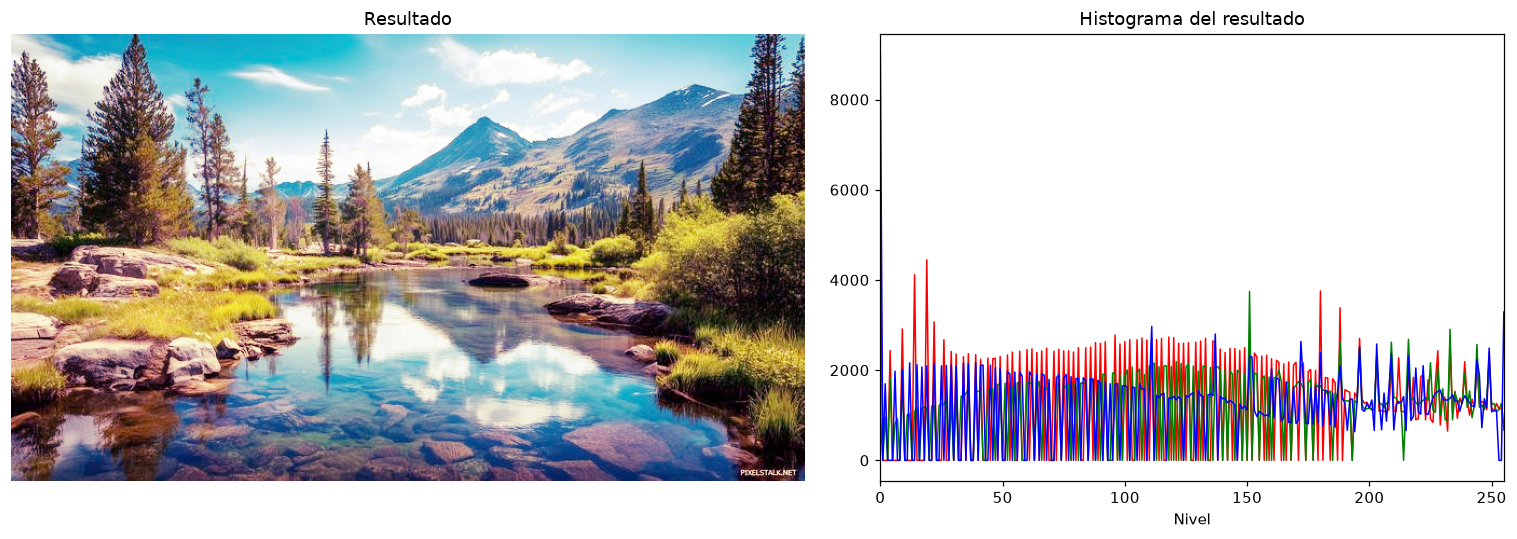

In [10]:
try:
    import ipywidgets as w
    from IPython.display import display
except ImportError:
    import sys, subprocess
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'ipywidgets'])
    import ipywidgets as w
    from IPython.display import display

def procesar(base, lum, gR, gG, gB, brillo, contraste):
    x = base.astype(np.float64)
    x = x * np.array([gR, gG, gB])                 # ganancia por color
    x = (x - 127.5) * contraste + 127.5 + brillo    # contraste y brillo
    x = np.clip(x, 0, 255) / 255.0
    x = x ** (1.0 / lum)                            # luminosidad (gamma)
    return (np.clip(x, 0, 1) * 255).astype(np.uint8)

def actualizar(lum, gR, gG, gB, brillo, contraste, usar_ecualizada):
    base = imgUnida if usar_ecualizada else img
    res = procesar(base, lum, gR, gG, gB, brillo, contraste)
    fig, ax = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={'width_ratios': [1.3, 1]})
    ax[0].imshow(res); ax[0].axis('off'); ax[0].set_title('Resultado')
    for i, col in enumerate(['red', 'green', 'blue']):
        ax[1].plot(histograma(res[:, :, i]), color=col, lw=1)
    ax[1].set_xlim(0, 255); ax[1].set_title('Histograma del resultado'); ax[1].set_xlabel('Nivel')
    plt.tight_layout(); plt.show()

def slider(v, a, b, paso, desc):
    return w.FloatSlider(value=v, min=a, max=b, step=paso, description=desc,
                         continuous_update=False, style={'description_width': '90px'},
                         layout=w.Layout(width='420px'))

controles = dict(
    lum=slider(1.2, 0.2, 3.0, 0.05, 'Luminosidad'),
    gR=slider(1.0, 0.0, 2.0, 0.05, 'Rojo'),
    gG=slider(1.0, 0.0, 2.0, 0.05, 'Verde'),
    gB=slider(1.0, 0.0, 2.0, 0.05, 'Azul'),
    brillo=slider(0, -100, 100, 1, 'Brillo'),
    contraste=slider(1.0, 0.2, 3.0, 0.05, 'Contraste'),
    usar_ecualizada=w.Checkbox(value=True, description='Usar ecualizada'),
)
ui = w.VBox(list(controles.values()))
salida = w.interactive_output(actualizar, controles)
display(ui, salida)

# Vista previa directa para visualización inmediata
actualizar(1.2, 1.0, 1.0, 1.0, 0, 1.0, True)
